In [1]:
# Import the required libraries
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score

In [2]:
# Load the Wine dataset
wine = load_wine()

# Extract the feature matrix and actual class labels
X = wine.data
y = wine.target

# Display dataset dimensions and feature names
print("Dataset Dimensions:", X.shape)
print("\nNumber of Samples:", X.shape[0])
print("Number of Features:", X.shape[1])

print("\nFeature Names:")
for feature in wine.feature_names:
    print(feature)

Dataset Dimensions: (178, 13)

Number of Samples: 178
Number of Features: 13

Feature Names:
alcohol
malic_acid
ash
alcalinity_of_ash
magnesium
total_phenols
flavanoids
nonflavanoid_phenols
proanthocyanins
color_intensity
hue
od280/od315_of_diluted_wines
proline


In [3]:
# Standardize the 13 numerical features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Standardization completed successfully.")
print("Standardized Data Shape:", X_scaled.shape)

Standardization completed successfully.
Standardized Data Shape: (178, 13)


In [4]:
# Create the K-means model with 3 clusters
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

# Fit the model and predict cluster assignments
clusters = kmeans.fit_predict(X_scaled)

print("K-means clustering completed.")
print("Number of Clusters:", kmeans.n_clusters)

c:\Users\koust\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\koust\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\Users\koust\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\koust\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^

K-means clustering completed.
Number of Clusters: 3


c:\Users\koust\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


In [5]:
# Count the samples assigned to each cluster
cluster_counts = np.bincount(clusters, minlength=3)

print("Number of Samples in Each Cluster:")
for cluster_id, count in enumerate(cluster_counts):
    print(f"Cluster {cluster_id}: {count} samples")

# Display cluster centroids in the standardized 13-dimensional space
print("\nCluster Centroids (Standardized Feature Space):")
print(kmeans.cluster_centers_)

Number of Samples in Each Cluster:
Cluster 0: 65 samples
Cluster 1: 51 samples
Cluster 2: 62 samples

Cluster Centroids (Standardized Feature Space):
[[-0.92607185 -0.39404154 -0.49451676  0.17060184 -0.49171185 -0.07598265
   0.02081257 -0.03353357  0.0582655  -0.90191402  0.46180361  0.27076419
  -0.75384618]
 [ 0.16490746  0.87154706  0.18689833  0.52436746 -0.07547277 -0.97933029
  -1.21524764  0.72606354 -0.77970639  0.94153874 -1.16478865 -1.29241163
  -0.40708796]
 [ 0.83523208 -0.30380968  0.36470604 -0.61019129  0.5775868   0.88523736
   0.97781956 -0.56208965  0.58028658  0.17106348  0.47398365  0.77924711
   1.12518529]]


In [6]:
# Reduce the standardized 13-dimensional data to 2 dimensions
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Transform the cluster centroids into the same PCA space
centroids_pca = pca.transform(kmeans.cluster_centers_)

print("PCA completed successfully.")
print("PCA Data Shape:", X_pca.shape)

print("\nExplained Variance Ratio:")
print(pca.explained_variance_ratio_)

print(
    "\nTotal Variance Preserved:",
    round(np.sum(pca.explained_variance_ratio_) * 100, 2),
    "%"
)

PCA completed successfully.
PCA Data Shape: (178, 2)

Explained Variance Ratio:
[0.36198848 0.1920749 ]

Total Variance Preserved: 55.41 %


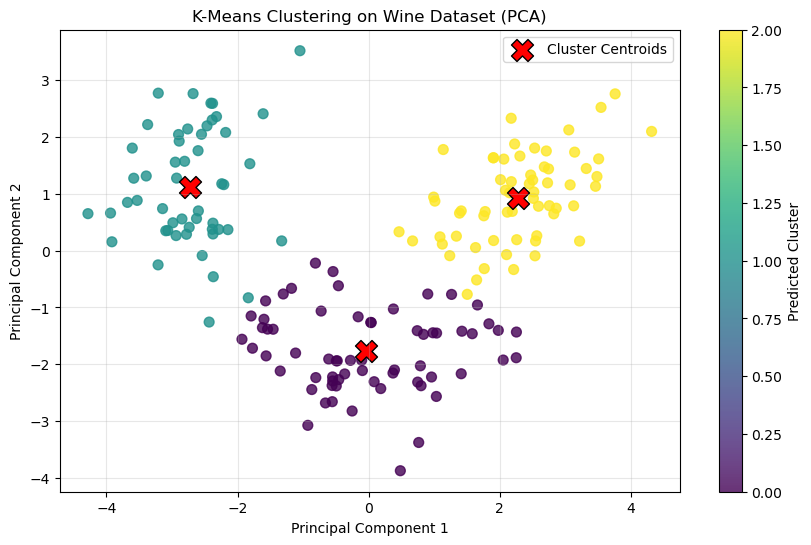

In [7]:
# Plot the predicted clusters in the 2D PCA space
plt.figure(figsize=(10, 6))

scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=clusters,
    cmap="viridis",
    s=50,
    alpha=0.8
)

# Plot the cluster centroids
plt.scatter(
    centroids_pca[:, 0],
    centroids_pca[:, 1],
    marker="X",
    s=250,
    c="red",
    edgecolors="black",
    label="Cluster Centroids"
)

plt.title("K-Means Clustering on Wine Dataset (PCA)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend()
plt.colorbar(scatter, label="Predicted Cluster")
plt.grid(True, alpha=0.3)
plt.show()

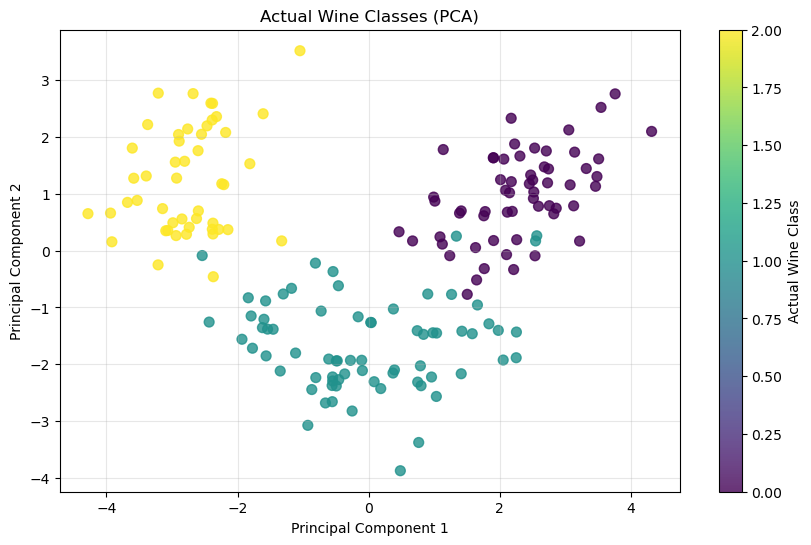

In [8]:
# Plot the actual wine classes in the same PCA space
plt.figure(figsize=(10, 6))

scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=y,
    cmap="viridis",
    s=50,
    alpha=0.8
)

plt.title("Actual Wine Classes (PCA)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.colorbar(scatter, label="Actual Wine Class")
plt.grid(True, alpha=0.3)
plt.show()

In [9]:
# Compare predicted clusters with actual wine class labels
ari = adjusted_rand_score(y, clusters)

print("Adjusted Rand Index (ARI):", round(ari, 4))

Adjusted Rand Index (ARI): 0.8975


In [10]:
# Display a summary of the experiment
print("=" * 45)
print("K-MEANS CLUSTERING: WINE DATASET")
print("=" * 45)

print("Total Samples:", X.shape[0])
print("Total Features:", X.shape[1])
print("Number of Clusters:", kmeans.n_clusters)

print("\nCluster Distribution:")
for i, count in enumerate(cluster_counts):
    print(f"Cluster {i}: {count} samples")

print("\nARI Score:", round(ari, 4))

print("\nPCA Explained Variance:")
print(f"PC1: {pca.explained_variance_ratio_[0] * 100:.2f}%")
print(f"PC2: {pca.explained_variance_ratio_[1] * 100:.2f}%")
print(
    "Total:",
    f"{np.sum(pca.explained_variance_ratio_) * 100:.2f}%"
)

K-MEANS CLUSTERING: WINE DATASET
Total Samples: 178
Total Features: 13
Number of Clusters: 3

Cluster Distribution:
Cluster 0: 65 samples
Cluster 1: 51 samples
Cluster 2: 62 samples

ARI Score: 0.8975

PCA Explained Variance:
PC1: 36.20%
PC2: 19.21%
Total: 55.41%


In [11]:
# Import required libraries
import numpy as np
import matplotlib.pyplot as plt

from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import pdist

In [12]:
# Marks of five students
students = ['A', 'B', 'C', 'D', 'E']
marks = np.array([[10], [12], [25], [27], [50]])

# Display the dataset
print("Student Marks:")
for student, mark in zip(students, marks.flatten()):
    print(f"Student {student}: {mark}")

Student Marks:
Student A: 10
Student B: 12
Student C: 25
Student D: 27
Student E: 50


In [13]:
# Calculate Euclidean distances and perform single-linkage clustering
Z = linkage(marks, method='single', metric='euclidean')

# Form exactly two clusters
clusters = fcluster(Z, t=2, criterion='maxclust')

# Display cluster assignments
print("\nCluster Assignments:")
for student, cluster in zip(students, clusters):
    print(f"Student {student}: Cluster {cluster}")


Cluster Assignments:
Student A: Cluster 1
Student B: Cluster 1
Student C: Cluster 1
Student D: Cluster 1
Student E: Cluster 2


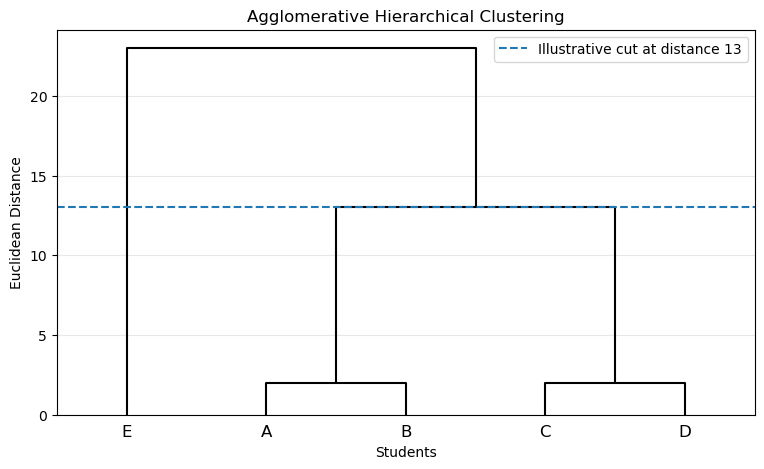

In [15]:
# Plot the dendrogram
plt.figure(figsize=(9, 5))

dendrogram(
    Z,
    labels=students,
    color_threshold=0,
    above_threshold_color='black'
)

plt.title("Agglomerative Hierarchical Clustering")
plt.xlabel("Students")
plt.ylabel("Euclidean Distance")
plt.axhline(y=13, linestyle='--', label='Illustrative cut at distance 13')
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.show()

In [16]:
%pip install scikit-fuzzy scikit-learn matplotlib


   ---------------------------------------- 0.0/920.8 kB ? eta -:--:--
   ---------------------------------------- 0.0/920.8 kB ? eta -:--:--
   ----------- ---------------------------- 262.1/920.8 kB ? eta -:--:--
   ---------------------- ----------------- 524.3/920.8 kB 1.3 MB/s eta 0:00:01
   ---------------------------------- ----- 786.4/920.8 kB 1.2 MB/s eta 0:00:01
   ---------------------------------------- 920.8/920.8 kB 1.2 MB/s eta 0:00:00


In [17]:
# Import required libraries
import numpy as np
import matplotlib.pyplot as plt
import skfuzzy as fuzz

from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score

In [18]:
# Load the Breast Cancer Wisconsin dataset
data = load_breast_cancer()

X = data.data
y = data.target

# Display dataset information
print("Dataset Shape:", X.shape)
print("Number of Samples:", X.shape[0])
print("Number of Features:", X.shape[1])
print("Actual Classes:", data.target_names)

print("\nFeature Names:")
print(data.feature_names)

Dataset Shape: (569, 30)
Number of Samples: 569
Number of Features: 30
Actual Classes: ['malignant' 'benign']

Feature Names:
['mean radius' 'mean texture' 'mean perimeter' 'mean area'
 'mean smoothness' 'mean compactness' 'mean concavity'
 'mean concave points' 'mean symmetry' 'mean fractal dimension'
 'radius error' 'texture error' 'perimeter error' 'area error'
 'smoothness error' 'compactness error' 'concavity error'
 'concave points error' 'symmetry error' 'fractal dimension error'
 'worst radius' 'worst texture' 'worst perimeter' 'worst area'
 'worst smoothness' 'worst compactness' 'worst concavity'
 'worst concave points' 'worst symmetry' 'worst fractal dimension']


In [19]:
# Standardize all 30 numerical features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Standardization completed.")
print("Standardized Data Shape:", X_scaled.shape)

Standardization completed.
Standardized Data Shape: (569, 30)


In [20]:
# Transpose data for scikit-fuzzy
X_fcm = X_scaled.T

# Apply Fuzzy C-Means with 2 clusters and fuzziness m=2
centers, membership, u0, distance, objective, iterations, fpc = (
    fuzz.cluster.cmeans(
        data=X_fcm,
        c=2,
        m=2,
        error=0.005,
        maxiter=1000,
        seed=42
    )
)

print("Fuzzy C-Means clustering completed.")
print("Number of Clusters:", centers.shape[0])
print("Fuzziness Parameter (m): 2")
print("Number of Iterations:", iterations)
print("Fuzzy Partition Coefficient (FPC):", round(fpc, 4))

Fuzzy C-Means clustering completed.
Number of Clusters: 2
Fuzziness Parameter (m): 2
Number of Iterations: 15
Fuzzy Partition Coefficient (FPC): 0.6558


In [21]:
# Display the cluster centres
print("Cluster Centres (Standardized Feature Space):\n")

for i, center in enumerate(centers):
    print(f"Cluster {i}:")
    print(np.round(center, 4))
    print()

Cluster Centres (Standardized Feature Space):

Cluster 0:
[-0.4347 -0.2578 -0.4503 -0.4272 -0.2916 -0.4829 -0.5163 -0.5314 -0.2814
 -0.145  -0.3816 -0.0753 -0.3833 -0.3467 -0.0646 -0.3499 -0.302  -0.3837
 -0.0763 -0.2353 -0.4616 -0.2558 -0.4749 -0.4419 -0.2858 -0.4433 -0.4819
 -0.5267 -0.2547 -0.3063]

Cluster 1:
[0.786  0.4034 0.8089 0.7692 0.4725 0.7822 0.867  0.9185 0.4519 0.1575
 0.6509 0.0516 0.6421 0.6025 0.027  0.4961 0.4292 0.5725 0.0561 0.2856
 0.8378 0.4184 0.8531 0.8016 0.4861 0.7223 0.7952 0.8988 0.4325 0.4572]



In [22]:
# Display membership values for the first 10 samples
print("Membership Values for First 10 Samples:")
print("Sample\tCluster 0\tCluster 1")

for i in range(10):
    print(
        f"{i + 1}\t"
        f"{membership[0, i]:.4f}\t\t"
        f"{membership[1, i]:.4f}"
    )

Membership Values for First 10 Samples:
Sample	Cluster 0	Cluster 1
1	0.2953		0.7047
2	0.3414		0.6586
3	0.1313		0.8687
4	0.4117		0.5883
5	0.2663		0.7337
6	0.3768		0.6232
7	0.2725		0.7275
8	0.3246		0.6754
9	0.3260		0.6740
10	0.3938		0.6062


In [23]:
# Assign each sample to the cluster with maximum membership
predicted_clusters = np.argmax(membership, axis=0)

# Count samples in each cluster
cluster_counts = np.bincount(predicted_clusters, minlength=2)

print("Number of Samples in Each Cluster:")
for i, count in enumerate(cluster_counts):
    print(f"Cluster {i}: {count} samples")

print("\nFirst 10 Predicted Cluster Labels:")
print(predicted_clusters[:10])

Number of Samples in Each Cluster:
Cluster 0: 370 samples
Cluster 1: 199 samples

First 10 Predicted Cluster Labels:
[1 1 1 1 1 1 1 1 1 1]


In [24]:
# Reduce 30 standardized features to 2 principal components
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print("PCA Data Shape:", X_pca.shape)

print(
    "Total Variance Preserved:",
    round(np.sum(pca.explained_variance_ratio_) * 100, 2),
    "%"
)

PCA Data Shape: (569, 2)
Total Variance Preserved: 63.24 %


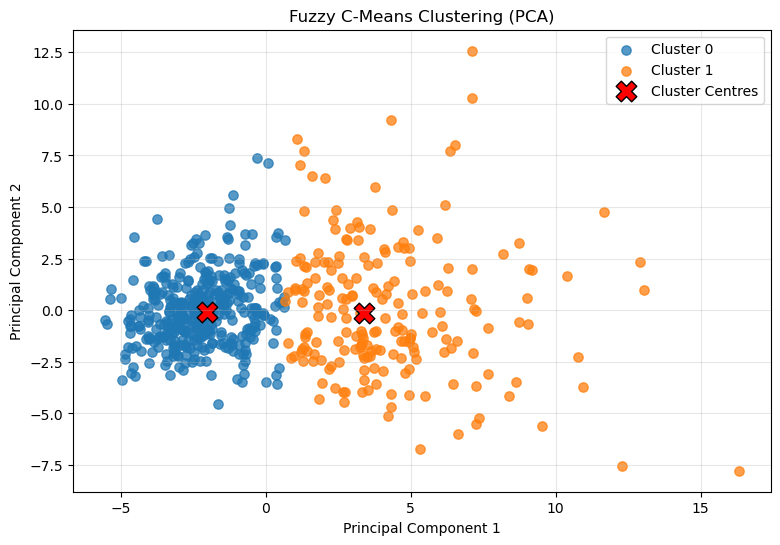

In [25]:
# Plot predicted clusters in PCA space
plt.figure(figsize=(9, 6))

for cluster_id in range(2):
    mask = predicted_clusters == cluster_id

    plt.scatter(
        X_pca[mask, 0],
        X_pca[mask, 1],
        label=f"Cluster {cluster_id}",
        s=45,
        alpha=0.75
    )

# Project the 30-dimensional cluster centres into PCA space
centers_pca = pca.transform(centers)

plt.scatter(
    centers_pca[:, 0],
    centers_pca[:, 1],
    marker="X",
    s=220,
    c="red",
    edgecolors="black",
    label="Cluster Centres"
)

plt.title("Fuzzy C-Means Clustering (PCA)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [27]:
# Compare predicted clusters with actual class labels
ari = adjusted_rand_score(y, predicted_clusters)

print("Adjusted Rand Index (ARI):", round(ari, 4))

Adjusted Rand Index (ARI): 0.6829


In [28]:
# Display the final experiment summary
print("=" * 50)
print("FUZZY C-MEANS: BREAST CANCER WISCONSIN DATASET")
print("=" * 50)

print("Total Samples:", X.shape[0])
print("Total Features:", X.shape[1])
print("Number of Clusters:", centers.shape[0])
print("Fuzziness Parameter:", 2)

print("\nCluster Distribution:")
for i, count in enumerate(cluster_counts):
    print(f"Cluster {i}: {count} samples")

print("\nIterations:", iterations)
print("Fuzzy Partition Coefficient:", round(fpc, 4))
print("Adjusted Rand Index:", round(ari, 4))
print(
    "PCA Variance Preserved:",
    f"{np.sum(pca.explained_variance_ratio_) * 100:.2f}%"
)

FUZZY C-MEANS: BREAST CANCER WISCONSIN DATASET
Total Samples: 569
Total Features: 30
Number of Clusters: 2
Fuzziness Parameter: 2

Cluster Distribution:
Cluster 0: 370 samples
Cluster 1: 199 samples

Iterations: 15
Fuzzy Partition Coefficient: 0.6558
Adjusted Rand Index: 0.6829
PCA Variance Preserved: 63.24%
